<a href="https://colab.research.google.com/github/luiskeine/ColabNotes/blob/main/Data_Cleaning_in_Python_Essential_Training.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Table of Contents

- [1. Bad Data](#1.-BAD-DATA)
  - [1.1 Missing Values](#01_02-Missing-Values)
  - [1.2 Bad Values](#01_03-Bad-Values)
  - [1.3 Duplicates](#01_04-Duplicates)
- [2. Causes of Errors](#2.-CAUSES-OF-ERRORS)
- [3. Detecting Errors](#3.-DETECTING-ERRORS)
  - [3.1 Schemas](#03_01-Schemas)
  - [3.2 Validation](#03_02-Validation)
  - [3.3 Finding Missing Data](#03_03-Finding-Missning-Data)
  - [3.4 Domain Knowledge](#03_04-Domain-Knowledge)
  - [3.5 Subgroups](#03_05-Subgroups)
  - [3.6 Advanced Schema Validation](#03_06-Using-Copilot-to-build-Schema)
- [4. Preventing Errors](#4.-Preventing-Errors)
  - [4.1 Serialization Formats](#Serialization-Formats)
  - [4.2 Digital Signature](#04_02-Digital-Signature)
  - [4.3 Data Pipelines and Automation](#04_03-Data-Pipelines-and-Automation)
  - [4.4 Transactions](#04_04-Transactions)
  - [4.5 Data Organization and Tidy Data](#04_05-Data-Organization-and-Tidy-data)
  - [4.6 Process and Data Quality Metrics](#04_05-Process-and-Data-Quality-Metrics)
- [5. Renaming Fields & Formatting](#REANAMING-FIELDS)
  - [5.1 Renaming Fields](#05_01-Renaming-Fields)
  - [5.2 Fixing Types](#05_02-Fixing-Types)
  - [5.3 Joining and Splitting Data](#05_03-Joining-and-Splitting-Data)
  - [5.4 Deleting Bad Data](#05_04-Deleting-Bad-Data)
  - [5.5 Filling Missing Values](#05_05-Filling-Missing-Values)
  - [5.6 Reshaping Data](#05_06-Reshaping-Data)
  - [5.7 Workshop Challenge Solution](#Challenge-05)

#1. BAD DATA
##01_02 Missing Values

In [ ]:
# %%
import pandas as pd

In [ ]:
# %%
df = pd.read_csv('cart.csv', parse_dates=['date'])
df

,date,name,amount,price
0,2021-03-01,carrot,7.0,5.73
1,2021-03-01,egg,12.0,1.70
2,2021-03-01,milk,NaN,3.57
3,2021-03-01,potato,2.0,NaN
4,NaT,tomato,6.0,1.52
5,2021-03-02,potato,3.0,2.17
6,2021-03-03,NaN,5.0,3.68


In [ ]:
df.dtypes

,0
date,datetime64[ns]
name,object
amount,float64
price,float64


In [ ]:
df['amount'].astype('Int32')

,amount
0,7
1,12
2,<NA>
3,2
4,6
5,3
6,5


In [ ]:
df.isnull()

,date,name,amount,price
0,False,False,False,False
1,False,False,False,False
2,False,False,True,False
3,False,False,False,True
4,True,False,False,False
5,False,False,False,False
6,False,True,False,False


In [ ]:
df.isnull().any(axis=1)

,0
0,False
1,False
2,True
3,True
4,True
5,False
6,True


##01_03 Bad Values

In [ ]:
# %%
import pandas as pd

df = pd.read_csv('metrics.csv', parse_dates=['time'])
df.sample(10)

,time,name,value
72,2021-07-13 14:37:26.832,mem,2.274937e+08
82,2021-07-13 14:37:31.617,cpu,3.719000e+01
44,2021-07-13 14:37:13.434,mem,2.275479e+08
4,2021-07-13 14:36:54.294,mem,2.275157e+08
41,2021-07-13 14:37:11.520,cpu,2.804000e+01
40,2021-07-13 14:37:11.520,mem,2.275560e+08
51,2021-07-13 14:37:16.305,mem,2.275561e+08
26,2021-07-13 14:37:04.821,mem,2.275265e+08
52,2021-07-13 14:37:17.262,cpu,2.997000e+01
6,2021-07-13 14:36:55.251,mem,2.950000e+02


In [ ]:
df.groupby('name').describe()

time                                                             \
     count                           mean                         min   
name                                                                    
CPU      1  2021-07-13 14:36:59.079000064  2021-07-13 14:36:59.079000   
cpu     49  2021-07-13 14:37:16.168285696  2021-07-13 14:36:52.380000   
mem     50  2021-07-13 14:37:15.826500096  2021-07-13 14:36:52.380000   

                                                                    \
                                25%                            50%   
name                                                                 
CPU   2021-07-13 14:36:59.079000064  2021-07-13 14:36:59.079000064   
cpu   2021-07-13 14:37:04.820999936  2021-07-13 14:37:16.304999936   
mem   2021-07-13 14:37:04.103249920  2021-07-13 14:37:15.826499840   

                                                                     value  \
                                75%                         max  std count   
name                                                                         
CPU   2021-07-13 14:36:59.079000064  2021-07-13 14:36:59.079000  NaN   1.0   
cpu   2021-07-13 14:37:27.788999936  2021-07-13 14:37:39.273000  NaN  49.0   
mem   2021-07-13 14:37:27.549750016  2021-07-13 14:37:39.273000  NaN  50.0   

                                                                      \
              mean     min           25%           50%           75%   
name                                                                   
CPU   3.040000e+01   30.40  3.040000e+01  3.040000e+01  3.040000e+01   
cpu   3.645633e+01  -32.14  2.956000e+01  3.157000e+01  3.507000e+01   
mem   2.229711e+08  295.00  2.275070e+08  2.275188e+08  2.275342e+08   

                                 
              max           std  
name                             
CPU          30.4           NaN  
cpu         300.9  3.977927e+01  
mem   227556054.0  3.217637e+07

In [ ]:
df['name'].value_counts()

,count
name,
mem,50
cpu,49
CPU,1


array([<Axes: xlabel='time'>, <Axes: xlabel='time'>,
       <Axes: xlabel='time'>], dtype=object)

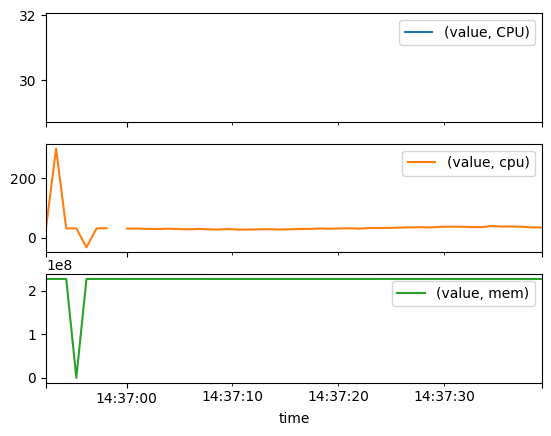

In [ ]:
pd.pivot(df, index='time', columns='name',).plot(subplots=True)

In [ ]:
df.query('name == "cpu" & (value < 0 | value > 100)')

,time,name,value
3,2021-07-13 14:36:53.337,cpu,300.90
9,2021-07-13 14:36:56.208,cpu,-32.14


In [ ]:
mem = df[df['name']=='mem']['value']
z_score = (mem - mem.mean()) / mem.std()
bad_mem = mem[z_score.abs() > 2]
# bad_mem
df.loc[bad_mem.index]

,time,name,value
6,2021-07-13 14:36:55.251,mem,295.0


##01_04 Duplicates

In [ ]:
# %%
import pandas as pd

# %%
df = pd.read_csv('cart (1).csv', parse_dates=['date'])
df

,date,name,amount,price
0,2021-03-01,carrot,7,5.73
1,2021-03-01,egg,12,1.70
2,2021-03-01,egg,12,1.20
3,2021-03-01,milk,1,3.57
4,2021-03-02,potato,3,2.17
5,2021-03-02,potato,3,2.17


In [ ]:
df.duplicated()
#2 is false because it has different price

,0
0,False
1,False
2,False
3,False
4,False
5,True


In [ ]:
df.duplicated(['date', 'name'])

,0
0,False
1,False
2,True
3,False
4,False
5,True


#2. CAUSES OF ERRORS
## Human Errors, Machine Errors, Design Errors

# 3. DETECTING ERRORS
##03_01 Schemas

In [ ]:
# %%
import pandas as pd

df = pd.read_csv('ships.csv')
df

,name,lat,lng
0,Black Pearl,20.664865,-80.709747
1,Cobra,20.664868,-80.709740
2,Flying Dutchman,20.664878,-80.709941
3,Empress,NaN,NaN


In [ ]:
df.dtypes

,0
name,object
lat,float64
lng,float64


##03_02 Validation

In [ ]:
import pandas as pd

df = pd.read_csv('ships.csv')
df

,name,lat,lng
0,Black Pearl,20.664865,-80.709747
1,Cobra,20.664868,-80.709740
2,Flying Dutchman,20.664878,-80.709941
3,Empress,NaN,NaN


In [ ]:
!pip install pandera

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.6/604.6 kB 5.0 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [pandera]


In [ ]:
import pandera as pa
import numpy as np

schema = pa.DataFrameSchema({
    'name' : pa.Column(pa.String),
    'lat' : pa.Column(pa.Float, nullable=True),
    'lng' :  pa.Column(pa.Float, nullable=True),
})

schema.validate(df)

,name,lat,lng
0,Black Pearl,20.664865,-80.709747
1,Cobra,20.664868,-80.709740
2,Flying Dutchman,20.664878,-80.709941
3,Empress,NaN,NaN


##03_03 Finding Missning Data


In [ ]:
import pandas as pd

df = pd.read_csv('ships (6).csv')
df


,name,lat,lng
0,Black Pearl,20.664865,-80.709747
1,Cobra,20.664868,-80.709740
2,Flying Dutchman,20.664878,-80.709941
3,Empress,NaN,NaN
4,,20.664875,-80.709777


In [ ]:
df[df.isnull().any(axis=1)]

,name,lat,lng
3,Empress,NaN,NaN


In [ ]:
df.iloc[-1]['name']#doesnt recognize strings withs spaces such as number 4 name

' '

In [ ]:
df['name'] = df['name'].str.strip()
df.iloc[-1]['name']

''

In [ ]:
import numpy as np
mask = df['name'].str.strip() == ''# removing sapces to become an empty string
df.loc[mask, 'name'] = np.nan

In [ ]:
df[df.isnull().any(axis=1)]

,name,lat,lng
3,Empress,NaN,NaN
4,NaN,20.664875,-80.709777


##03_04 Domain Knowledge

In [ ]:
import pandas as pd

df = pd.read_csv('ships.csv')
df

#-90 <= lat <= 90
#-180 <= lng <= 180

,name,lat,lng
0,Black Pearl,20.664865,-80.709747
1,Cobra,20.664868,-80.709740
2,Flying Dutchman,20.664878,-80.709941
3,Empress,NaN,NaN


In [ ]:
import pandera as pa
import numpy as np

schema = pa.DataFrameSchema({
    'name' : pa.Column(pa.String),
    'lat' : pa.Column(
        pa.Float,
        nullable=True,
        checks=pa.Check(
            lambda v: v >= -90 and v <= 90,
            element_wise=True,
            ),
    ),
    'lng' :  pa.Column(
        pa.Float,
        nullable=True,
        checks=pa.Check(
            lambda v: v >= -180 and v <= 180,
            element_wise=True,
            ),
    ),
})

schema.validate(df)

,name,lat,lng
0,Black Pearl,20.664865,-80.709747
1,Cobra,20.664868,-80.709740
2,Flying Dutchman,20.664878,-80.709941
3,Empress,NaN,NaN


## 03_05 Subgroups

In [ ]:
import pandas as pd

df = pd.read_csv('heights.csv')
df

,name,grade,height
0,Adam,1,31.7
1,Beth,1,74.9
2,Chris,12,72.3
3,Dana,12,61.8


In [ ]:
max_heights = pd.DataFrame([
    [1,32],#gradw 1 max height 32
], columns=['grade', 'max_height'])
max_heights

,grade,max_height
0,1,32


In [ ]:
mdf = pd.merge(df, max_heights, how='left')
mdf

,name,grade,height,max_height
0,Adam,1,31.7,32.0
1,Beth,1,74.9,32.0
2,Chris,12,72.3,NaN
3,Dana,12,61.8,NaN


In [ ]:
df[mdf['height'] > mdf['max_height']]

,name,grade,height
1,Beth,1,74.9


## 03_06 Using Copilot to build Schema

In [ ]:
# %%
import pandas as pd

df = pd.read_csv('ships.csv')
df
# %%
import pandera as pa
import numpy as np

schema = pa.DataFrameSchema({
    'name': pa.Column(pa.String),
    'lat': pa.Column(pa.Float),
    'lng': pa.Column(pa.Float),
})

schema.validate(df)


#ask Find more rules for the schema output is below

,name,lat,lng
0,Black Pearl,20.664865,-80.709747
1,Cobra,20.664868,-80.709740
2,Flying Dutchman,20.664878,-80.709941
3,Empress,NaN,NaN


### Exploring Advanced Validation Rules with Pandera
Let's expand our schema validation rules to include:
* **Custom column check** (e.g., ensuring `name` contains non-empty strings and no leading/trailing whitespace).
* **Nullable configurations** (explicitly setting who can be null).
* **Range checks with informative error messages**.

In [ ]:
import pandera as pa
import pandas as pd

# Defining a more robust schema
strict_schema = pa.DataFrameSchema({
    'name': pa.Column(
        pa.String,
        checks=[
            # Must not be empty or only whitespace
            pa.Check(lambda s: s.str.strip().str.len() > 0, error="Name cannot be empty or just spaces"),
        ],
        nullable=False
    ),
    'lat': pa.Column(
        pa.Float,
        checks=[
            pa.Check.in_range(-90.0, 90.0, error="Latitude must be between -90 and 90")
        ],
        nullable=True
    ),
    'lng': pa.Column(
        pa.Float,
        checks=[
            pa.Check.in_range(-180.0, 180.0, error="Longitude must be between -180 and 180")
        ],
        nullable=True
    )
})

# Let's test the validation schema against our ships dataframe
try:
    strict_schema.validate(df, lazy=True)
    print("Validation passed!")
except pa.errors.SchemaErrors as err:
    print("Validation failed! Here are the failures:")
    display(err.failure_cases)

Validation passed!


#Challenge! 03

In [ ]:
# %%
import pandas as pd

df = pd.read_csv('rides.csv')
df
# %%
# Find out all the rows that have bad values
# - Missing values are not allowed
# - A plate must be a combination of at least 3 upper case letters or digits
# - Distance must be bigger than 0

,name,plate,distance
0,Gomez,1XZ2,3.70
1,Morticia,NaN,2.10
2,Fester,,3.40
3,Lurch,Q38X3,-3.20
4,NaN,03A,14.30
5,Wednesday,A,0.30
6,Pugsley,ZF003,153.14


In [ ]:
df.dtypes

,0
name,object
plate,object
distance,float64


In [ ]:
# - Missing values are not allowe
null_mask = df.isna().any(axis=1)
df[null_mask]

,name,plate,distance
1,Morticia,NaN,2.1
4,NaN,03A,14.3


In [ ]:
# - A plate must be a combination of at least 3 upper case letters or digits

# r - Tells Python to treat the string as a raw string
# ^ - Start of the string
# [A-Z] - Any uppercase letter from A to Z
# [0-9] - Any digit from 0 to 9
# [A-Z0-9] - Any uppercase letter OR digit
# {3,} - At least 3 characters
# $ - End of the string
# na=False - "If a plate is missing, treat it as False."

plate_mask = ~df['plate'].str.match(r'^[0-9A-Z]{3,}', na=False)
df[plate_mask]

,name,plate,distance
1,Morticia,NaN,2.1
2,Fester,,3.4
5,Wednesday,A,0.3


In [ ]:
# - Distance must be bigger than 0
dist_mask = df['distance'] <= 0
df[dist_mask]

,name,plate,distance
3,Lurch,Q38X3,-3.2


In [ ]:
Bad_val = null_mask | plate_mask | dist_mask
df[Bad_val]

,name,plate,distance
1,Morticia,NaN,2.1
2,Fester,,3.4
3,Lurch,Q38X3,-3.2
4,NaN,03A,14.3
5,Wednesday,A,0.3


#4. Preventing Errors
##Serialization Formats

In [ ]:
!pip install pyarrow

In [ ]:
import pandas as pd
import numpy as np

size = 5
df = pd.DataFrame({
    'time': pd.date_range('2021', freq='17s', periods=size),
    'name': ['cpu'] * size,
    'value': np.random.rand(size) * 40,
})
df

,time,name,value
0,2021-01-01 00:00:00,cpu,35.819547
1,2021-01-01 00:00:17,cpu,4.174719
2,2021-01-01 00:00:34,cpu,11.602094
3,2021-01-01 00:00:51,cpu,10.546012
4,2021-01-01 00:01:08,cpu,31.502814


In [ ]:
import pyarrow as pa

schema = pa.schema({
    'time': pa.timestamp('ms'),
    'name': pa.string(),
    'value': pa.float64(),
})


In [ ]:
out_file = 'metrics.parquet'
df.to_parquet(out_file, schema=schema)

In [ ]:
pd.read_parquet(out_file)

,time,name,value
0,2021-01-01 00:00:00,cpu,35.819547
1,2021-01-01 00:00:17,cpu,4.174719
2,2021-01-01 00:00:34,cpu,11.602094
3,2021-01-01 00:00:51,cpu,10.546012
4,2021-01-01 00:01:08,cpu,31.502814


##04_02 Digital Signature


In [ ]:
#Terminal Code
!cd Ch04/04_02

/bin/bash: line 1: cd: Ch04/04_02: No such file or directory


In [ ]:
!sha256sum metrics.csv
#long digital signature for the file

483f9bd1e905058e1a48f138e66d9e814626dedf5216688835983f093c581d1e  metrics.csv


In [ ]:
!sha256sum metrics.csv > sha256sum.txt#saved, it will add sha256sum.txt to your file

In [ ]:
!sha256sum -c sha256sum.txt#check

#if you change the file and paste step 3 it will fail

metrics.csv: OK


##04_03 Data Pipelines and Automation

In [ ]:
!pip install invoke

In [ ]:
import sqlite3

import pandas as pd
from invoke import task


def load_csv(csv_file):
    df = pd.read_csv(csv_file, parse_dates=['start', 'end'])
    return df


def validate(df):
    bad_time = df.query('start >= end')
    if len(bad_time) > 0:
        raise ValueError(bad_time)


@task
def etl(ctx, csv_file):
    df = load_csv(csv_file)
    validate(df)

    db_file = f'rides.db'
    conn = sqlite3.connect(db_file)
    df.to_sql('rides', conn, index=False, if_exists='append')

In [ ]:
#Start Terminal
!cd Ch04/04_03

/bin/bash: line 1: cd: Ch04/04_03: No such file or directory


In [ ]:
!invoke --list

Available tasks:

  etl



In [ ]:
!invoke etl --csv-file rides.csv
#error says that csv file does not have [start, end]

Traceback (most recent call last):
  File "/usr/local/bin/invoke", line 6, in <module>
    sys.exit(program.run())
             ~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/invoke/program.py", line 398, in run
    self.execute()
    ~~~~~~~~~~~~^^
  File "/usr/local/lib/python3.13/dist-packages/invoke/program.py", line 583, in execute
    executor.execute(*self.tasks)
    ~~~~~~~~~~~~~~~~^^^^^^^^^^^^^
  File "/usr/local/lib/python3.13/dist-packages/invoke/executor.py", line 143, in execute
    result = call.task(*args, **call.kwargs)
  File "/usr/local/lib/python3.13/dist-packages/invoke/tasks.py", line 139, in __call__
    result = self.body(*args, **kwargs)
  File "/content/tasks.py", line 20, in etl
    df = load_csv(csv_file)
  File "/content/tasks.py", line 8, in load_csv
    df = pd.read_csv(csv_file, parse_dates=['start', 'end'])
  File "/usr/local/lib/python3.13/dist-packages/pandas/io/parsers/readers.py", line 1026, in read_csv
    return _read(filepath_or_buf

In [ ]:
import pandas as pd
import glob

for file in glob.glob('/content/*rides*.csv'):
    df = pd.read_csv(file)
    print('\nFile:', file)
    print(df.columns.tolist())


File: /content/rides (15).csv
['car', 'start', 'end', 'charge']

File: /content/rides.csv
['name', 'plate', 'distance']

File: /content/rides (21).csv
['name', 'plate', 'distance']

File: /content/rides (12).csv
['name', 'plate', 'distance']


In [ ]:
!invoke etl --csv-file "rides (15).csv"
#that will add rides.db to your files

In [ ]:
#for colab
!apt-get update -qq
!apt-get install sqlite3 -y -qq

W: Skipping acquire of configured file 'main/source/Sources' as repository 'https://r2u.stat.illinois.edu/ubuntu noble InRelease' does not seem to provide it (sources.list entry misspelt?)
(Reading database ... 122813 files and directories currently installed.)
Preparing to unpack .../libsqlite3-dev_3.45.1-1ubuntu2.11_amd64.deb ...
Unpacking libsqlite3-dev:amd64 (3.45.1-1ubuntu2.11) over (3.45.1-1ubuntu2.8) ...
Preparing to unpack .../libsqlite3-0_3.45.1-1ubuntu2.11_amd64.deb ...
Unpacking libsqlite3-0:amd64 (3.45.1-1ubuntu2.11) over (3.45.1-1ubuntu2.8) ...
Selecting previously unselected package sqlite3.
Preparing to unpack .../sqlite3_3.45.1-1ubuntu2.11_amd64.deb ...
Unpacking sqlite3 (3.45.1-1ubuntu2.11) ...
Setting up libsqlite3-0:amd64 (3.45.1-1ubuntu2.11) ...
Setting up libsqlite3-dev:amd64 (3.45.1-1ubuntu2.11) ...
Setting up sqlite3 (3.45.1-1ubuntu2.11) ...
Processing triggers for man-db (2.12.0-4build2) ...
Processing triggers for libc-bin (2.39-0ubuntu8.9) ...
/sbin/ldconfig.r

In [ ]:
!sqlite3 rides.db
#type .schema
#then type. SELECT * FROM rides;
#.quit

SQLite version 3.45.1 2024-01-30 16:01:20
Enter ".help" for usage hints.
sqlite> .schema
CREATE TABLE IF NOT EXISTS "rides" (
"car" TEXT,
  "start" TIMESTAMP,
  "end" TIMESTAMP,
  "charge" REAL
);
sqlite> SELECT * FROM rides;
c1|2021-06-27 08:32:00|2021-06-27 08:47:00|17.3
c2|2021-06-27 09:07:00|2021-06-27 09:10:00|3.3
c2|2021-06-27 09:23:00|2021-06-27 09:42:00|30.6
c1|2021-06-27 09:33:00|2021-06-27 09:47:00|5.8
c1|2021-06-27 08:32:00|2021-06-27 08:47:00|17.3
c2|2021-06-27 09:07:00|2021-06-27 09:10:00|3.3
c2|2021-06-27 09:23:00|2021-06-27 09:42:00|30.6
c1|2021-06-27 09:33:00|2021-06-27 09:47:00|5.8
sqlite> .quit


##04_04 Transactions

This code demonstrates how to use transactions in a relational database with Python and SQLite. The main point is to ensure data integrity during the data insertion process: either all the data is inserted successfully, or if there's an error (like an invalid record), none of it is added. This prevents partial or corrupt data from entering your database. Using transactions like this is a key practice in building reliable data pipelines and cleaning workflows, helping you maintain high-quality, consistent data for analysis.

The error occurs because the database schema requires certain fields like latitude and longitude to have valid (non-null) values. When the code tries to insert a record with missing or invalid data in these fields, it violates the "NOT NULL" constraint, causing the error. This is intentional to ensure data quality. The transaction mechanism then rolls back the entire insertion to prevent partial or corrupt data from being saved, keeping your database clean and consistent.

In [ ]:
import pandas as pd

df = pd.read_csv('ships.csv')
df


,name,lat,lng
0,Black Pearl,20.664865,-80.709747
1,Cobra,20.664868,-80.709740
2,Flying Dutchman,20.664878,-80.709941
3,Empress,NaN,NaN


In [ ]:
import sqlite3

schema = '''
CREATE TABLE ships (
    name TEXT,
    lat FLOAT NOT NULL,
    lng FLOAT NOT NULL
);
'''

db_file = 'ships.db'
conn = sqlite3.connect(db_file)
conn.executescript(schema)
#rollback operation
try:
  with conn as cur:
    cur.execute('BEGIN')
    df.to_sql('ships', conn, if_exists='append', index=False)
finally:
  conn.close()

  #IntegrityError: NOT NULL constraint failed: ships.lat


IntegrityError: NOT NULL constraint failed: ships.lat

In [ ]:
#lets open the command line
!cd Ch04/04_04


/bin/bash: line 1: cd: Ch04/04_04: No such file or directory


In [ ]:
!sqlite3 ships.db
#type SELECT * FROM ships;
#.quit


#youll see no data

SQLite version 3.45.1 2024-01-30 16:01:20
Enter ".help" for usage hints.
sqlite> SELECT * FROM ships;
sqlite> .quit


## 04_05 Data Organization and Tidy data

- In Tidy Data, each row represents exactly one observation. This means that instead of having multiple measurements or variables in a single row (like CPU and memory together), the data is organized so that each row holds only one piece of information or measurement. This approach makes data easier to analyze and clean because each row corresponds to a single, clear observation.

The comparison between the two CSV formats is about how data is organized:

- In the wide format, each row contains multiple observations, like CPU and memory values together for the same time point.
In the narrow (or tidy) format, each row contains only one observation, with separate columns for time, the metric name (e.g., CPU or memory), and the value.

- This tidy format makes it easier to clean and analyze data because each row is a single, clear data point. It helps avoid confusion and simplifies processing, especially when working with Python for data cleaning and analysis.

In [ ]:
# Wide Format

# time	cpu	memory
# 2021-07-23T14:33:04	30.2	571.83
# 2021-07-23T14:44:05	32.9	524.72
# 2021-07-23T14:55:06	37.1	617.9

#Tidy Format or Narrow Format

# time	metric	value
# 2021-07-23 14:33:04	cpu	30.2
# 2021-07-23 14:44:05	cpu	32.9
# 2021-07-23 14:55:06	cpu	37.1
# 2021-07-23 14:33:04	memory	571.83
# 2021-07-23 14:44:05	memory	524.72
# 2021-07-23 14:55:06	memory	617.9

##04_05 Process and Data Quality Metrics

- What should you do if you have more than 10% of bad records?
- Should you reprocess bad data or ignore it?
- When should you stop everything and raise an alert?

In [ ]:
import pandas as pd

df = pd.read_csv('orders.csv', parse_dates=['time'])
df

,time,symbol,price,side
0,2027-06-01 08:02:00,MSFT,264.125209,bid
1,2027-06-01 08:02:17,MSFT,265.501745,ask
2,2027-06-01 08:02:34,IBM,145.990889,bid
3,2027-06-01 08:02:51,ORCL,78.809339,ask
4,2027-06-01 08:03:08,ORCL,78.621716,ask
5,2027-06-01 08:03:25,IBM,146.394603,bid
6,2027-06-01 08:03:42,MSFT,264.541463,bid
7,2027-06-01 08:03:59,MSFT,265.920656,ask
8,2027-06-01 08:04:16,ORCL,77.832466,bid
9,2027-06-01 08:04:33,MSFT,265.690728,ask


In [ ]:
def is_valid_row(row):
  if row['time'] < pd.Timestamp('1900'): # checks whether the date is earlier than January 1, 1900.
    return False

  if pd.isnull(row['symbol']) or row['symbol'].strip() == '': #checks whether the symbol is missing or empty.
    return False

  if row['price'] <= 0: # checks whether the price is zero or negative.
    return False

  return True

ok_df = df[df.apply(is_valid_row, axis=1)] #ok rows
#ok_df

In [ ]:
# run calculations

num_bad = len(df) - len(ok_df)
percent_bad = num_bad/len(df) * 100
print(f'{percent_bad:.2f}% bad rows')
if num_bad > 0:
  bad_rows = df[~df.index.isin(ok_df.index)]
  print('bad_rows: ')
  print(bad_rows)

5.00% bad rows
bad_rows: 
                  time symbol       price side
16 2027-06-01 08:06:32    NaN  265.443295  ask


#Challenge 04
"""
Load traffic.csv into "traffic" table in sqlite3 database.

Drop and report invalid rows.
- ip should be valid IP (see ipaddress)
- time must not be in the future
- path can't be empty
- status code must be a valid HTTP status code (see http.HTTPStatus)
- size can't be negative or empty

Report the percentage of bad rows. Fail the ETL if there are more than 5% bad rows
"""

In [ ]:
import sqlite3
from contextlib import closing
from http import HTTPStatus
from ipaddress import ip_address

import pandas as pd

status_codes = set(HTTPStatus)

max_bad_percent = 5


def is_valid_row(row):
    # ip should be valid IP (see ipaddress)
    try:
        ip_address(row['ip'])
    except ValueError:
        return False

    # time must not be in the future or older than 1 year
    now = pd.Timestamp.now()
    if row['time'] > now:
        return False

    # path can't be empty
    if pd.isnull(row['path']) or not row['path'].strip():
        return False

    # status code must be a valid HTTP status code (see http.HTTPStatus)
    if row['status'] not in status_codes:
        return False

    # size can't be negative or empty
    if pd.isnull(row['size']) or row['size'] < 0:
        return False

    return True


def etl(csv_file, db_file):
    df = pd.read_csv(csv_file, parse_dates=['time'])

    bad_rows = df[~df.apply(is_valid_row, axis=1)]
    if len(bad_rows) > 0:
        percent_bad = len(bad_rows)/len(df) * 100
        print(f'{len(bad_rows)} ({percent_bad:.2f}%) bad rows')
        if percent_bad >= max_bad_percent:
            raise ValueError(f'too many bad rows ({percent_bad:.2f}%)')

    df = df[~df.index.isin(bad_rows.index)]
    with closing(sqlite3.connect(db_file)) as conn:
        conn.execute('BEGIN')
        with conn:
            df.to_sql('traffic', conn, if_exists='append', index=False)

if __name__ == '__main__':
    etl('traffic (20).csv', 'traffic.db')

5 (3.91%) bad rows


In [ ]:
#Start Terminal
!cd CH04/solution/

/bin/bash: line 1: cd: CH04/solution/: No such file or directory


In [ ]:
!sqlite3 traffic.db
#.schema
#SELECT COUNT(ip) FROM traffic;

SQLite version 3.45.1 2024-01-30 16:01:20
Enter ".help" for usage hints.
sqlite> .schema
CREATE TABLE IF NOT EXISTS "traffic" (
"ip" TEXT,
  "time" TIMESTAMP,
  "path" TEXT,
  "status" INTEGER,
  "size" INTEGER
);
sqlite> SELECT COUNT(ip) FROM traffic;
1230
sqlite> .quit


#REANAMING FIELDS
##05_01 Renaming Fields

In [2]:
import pandas as pd

df = pd.read_csv('weather.csv', parse_dates=['DATE'])
df


,DATE,TMIN,TMAX
0,2021-04-25,18,28
1,2021-04-26,16,23
2,2021-04-27,17,24
3,2021-04-28,15,25
4,2021-04-29,17,28


In [6]:
df.rename(columns={
    'Date': 'date',
    'TMIN': 'min_temp',
    'TMAX': 'max_temp',
}, inplace=True)
df

,DATE,min_temp,max_temp
0,2021-04-25,18,28
1,2021-04-26,16,23
2,2021-04-27,17,24
3,2021-04-28,15,25
4,2021-04-29,17,28


In [8]:
df = pd.read_csv('donations.csv')
df

,1. First Name,2. Last Name,3. Donation Amount
0,Amy,Wang,200
1,Bender,Rodriguez,12
2,Philip,Fry,70


In [11]:
import re

def fix_col(col):
  """Fix column name
  >>> fix_col('1. First Name')
  'first_name'
  """
  return (
      re.sub(r'\d+\.\s+', '', col)
      .lower()
      .replace(' ', '_')
  )

df.rename(columns=fix_col, inplace=True)
df

,first_name,last_name,donation_amount
0,Amy,Wang,200
1,Bender,Rodriguez,12
2,Philip,Fry,70


##05_02 Fixing Types

In [13]:
import pandas as pd

df = pd.read_csv('points.csv')
df.dtypes

,0
x,int64
y,int64
color,object
visible,object


In [19]:
def asint(val):
    if isinstance(val, str):
        return int(val, base=0)
    return int(val)

df['color'] = df['color'].apply(asint)
df.dtypes

,0
x,int64
y,int64
color,int64
visible,object


In [22]:
bools = {
    'yes': True,
    'no': False,
}
df['visible'] = df['visible'].map(bools)
df.dtypes

,0
x,int64
y,int64
color,int64
visible,object


In [23]:
df

,x,y,color,visible
0,1,1,16711680,NaN
1,2,2,65280,NaN
2,3,3,255,NaN


## 05_03 Joining and Splitting Data

In [25]:
import pandas as pd

csv_file = '2021-06.csv'

df = pd.read_csv(csv_file)
df

,day,time,client
0,1,09:00-11:00,ecorp
1,1,12:00-18:00,allsafe
2,2,10:00-19:30,allsafe
3,3,11:30-17:00,ecorp


In [27]:
df['date'] = csv_file[:-len('.csv')] #added date column
df

,day,time,client,date
0,1,09:00-11:00,ecorp,2021-06
1,1,12:00-18:00,allsafe,2021-06
2,2,10:00-19:30,allsafe,2021-06
3,3,11:30-17:00,ecorp,2021-06


In [29]:
times = df['time'].str.split('-', expand=True)
times.columns = ['start', 'end']
times

,start,end
0,09:00,11:00
1,12:00,18:00
2,10:00,19:30
3,11:30,17:00


In [31]:
df = pd.concat([df, times], axis=1)#get the dataframe start end
df

,day,time,client,date,start,end,start,end
0,1,09:00-11:00,ecorp,2021-06,09:00,11:00,09:00,11:00
1,1,12:00-18:00,allsafe,2021-06,12:00,18:00,12:00,18:00
2,2,10:00-19:30,allsafe,2021-06,10:00,19:30,10:00,19:30
3,3,11:30-17:00,ecorp,2021-06,11:30,17:00,11:30,17:00


In [37]:
# df['start'] = pd.to_datetime(
#     df['date'].str.cat(df['start'], sep='T')
# )
# df['end'] = pd.to_datetime(
#     df['date'].str.cat(df['end'], sep='T')
# )
# df

#colab form
# Using .copy() ensures df is an independent DataFrame, eliminating the SettingWithCopyWarning
df = df.loc[:, ~df.columns.duplicated()].copy()

# Now perform the string concatenation and convert to datetime safely
df['start'] = pd.to_datetime(
    df['date'].astype(str) + '-' + df['day'].astype(str).str.zfill(2) + 'T' + times['start']
    )
df['end'] = pd.to_datetime(
    df['date'].astype(str) + '-' + df['day'].astype(str).str.zfill(2) + 'T' + times['end']
    )
df

,day,time,client,date,start,end
0,1,09:00-11:00,ecorp,2021-06,2021-06-01 09:00:00,2021-06-01 11:00:00
1,1,12:00-18:00,allsafe,2021-06,2021-06-01 12:00:00,2021-06-01 18:00:00
2,2,10:00-19:30,allsafe,2021-06,2021-06-02 10:00:00,2021-06-02 19:30:00
3,3,11:30-17:00,ecorp,2021-06,2021-06-03 11:30:00,2021-06-03 17:00:00


In [38]:
(df['end'] - df['start']).sum()

Timedelta('0 days 23:00:00')

##05_04 Deleting Bad Data

In [40]:
import pandas as pd

df = pd.read_csv('rides.csv')
df

,name,plate,distance
0,Gomez,1XZ2,3.70
1,Morticia,NaN,2.10
2,Fester,,3.40
3,Lurch,Q38X3,-3.20
4,NaN,03A,14.30
5,Wednesday,A,0.30
6,Pugsley,ZF003,153.14


In [42]:
mask = df.eval('name.isnull() | distance <=0')
mask

,0
0,False
1,False
2,False
3,True
4,True
5,False
6,False


In [44]:
df = df[~mask]
df

/tmp/ipykernel_2678/4169883900.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  df = df[~mask]


,name,plate,distance
0,Gomez,1XZ2,3.70
1,Morticia,NaN,2.10
2,Fester,,3.40
5,Wednesday,A,0.30
6,Pugsley,ZF003,153.14


##05_05 Filling Missing Values

In [45]:
import pandas as pd


df = pd.read_csv('cart.csv', parse_dates=['date'])
df

,date,name,amount,price
0,2021-03-01,carrot,7.0,5.73
1,2021-03-01,egg,12.0,1.70
2,2021-03-01,milk,NaN,3.57
3,2021-03-01,potato,2.0,NaN
4,NaT,tomato,6.0,1.52
5,2021-03-02,potato,3.0,2.17
6,2021-03-03,NaN,5.0,3.68


In [47]:
df['amount'].fillna(1, inplace=True)
df

/tmp/ipykernel_2678/3781322780.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['amount'].fillna(1, inplace=True)


,date,name,amount,price
0,2021-03-01,carrot,7.0,5.73
1,2021-03-01,egg,12.0,1.70
2,2021-03-01,milk,1.0,3.57
3,2021-03-01,potato,2.0,NaN
4,NaT,tomato,6.0,1.52
5,2021-03-02,potato,3.0,2.17
6,2021-03-03,NaN,5.0,3.68


In [49]:
most_common = df['name'].mode()[0]
df['name'].fillna(most_common, inplace=True)
df

/tmp/ipykernel_2678/3136735520.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['name'].fillna(most_common, inplace=True)


,date,name,amount,price
0,2021-03-01,carrot,7.0,5.73
1,2021-03-01,egg,12.0,1.70
2,2021-03-01,milk,1.0,3.57
3,2021-03-01,potato,2.0,NaN
4,NaT,tomato,6.0,1.52
5,2021-03-02,potato,3.0,2.17
6,2021-03-03,potato,5.0,3.68


In [51]:
df['date'].fillna(method='ffill', inplace=True)#ffill - forward fill
df

/tmp/ipykernel_2678/3852126292.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['date'].fillna(method='ffill', inplace=True)
/tmp/ipykernel_2678/3852126292.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['date'].fillna(method='ffill', inplace=True)


,date,name,amount,price
0,2021-03-01,carrot,7.0,5.73
1,2021-03-01,egg,12.0,1.70
2,2021-03-01,milk,1.0,3.57
3,2021-03-01,potato,2.0,NaN
4,2021-03-01,tomato,6.0,1.52
5,2021-03-02,potato,3.0,2.17
6,2021-03-03,potato,5.0,3.68


In [53]:
import numpy as np
prices = df.groupby('name')['price'].transform(np.mean)
prices

/tmp/ipykernel_2678/3206615725.py:2: FutureWarning: The provided callable <function mean at 0x78ba6217e3e0> is currently using SeriesGroupBy.mean. In a future version of pandas, the provided callable will be used directly. To keep current behavior pass the string "mean" instead.
  prices = df.groupby('name')['price'].transform(np.mean)


,price
0,5.730
1,1.700
2,3.570
3,2.925
4,1.520
5,2.925
6,2.925


In [54]:
df['price'].fillna(prices, inplace=True)
df

/tmp/ipykernel_2678/1373701489.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['price'].fillna(prices, inplace=True)


,date,name,amount,price
0,2021-03-01,carrot,7.0,5.730
1,2021-03-01,egg,12.0,1.700
2,2021-03-01,milk,1.0,3.570
3,2021-03-01,potato,2.0,2.925
4,2021-03-01,tomato,6.0,1.520
5,2021-03-02,potato,3.0,2.170
6,2021-03-03,potato,5.0,3.680


##05_06 Reshaping Data


In [60]:
import pandas as pd

df = pd.read_csv('metrics.csv', parse_dates=['time'])
df

,time,cpu,memory
0,2021-07-23 14:33:04,30.2,571.83
1,2021-07-23 14:44:05,32.9,524.72
2,2021-07-23 14:55:06,37.1,617.90


In [61]:
df = pd.melt(
    df,
    value_vars=['cpu', 'memory'],
    id_vars=['time'],
    var_name='metric',
)
df

,time,metric,value
0,2021-07-23 14:33:04,cpu,30.20
1,2021-07-23 14:44:05,cpu,32.90
2,2021-07-23 14:55:06,cpu,37.10
3,2021-07-23 14:33:04,memory,571.83
4,2021-07-23 14:44:05,memory,524.72
5,2021-07-23 14:55:06,memory,617.90


#Challenge 05


In [78]:
import pandas as pd
import numpy as np

df = pd.read_csv('/content/workshops.csv')
display(df)
# %%
"""
Fix the data frame. At the end, row should have the following columns:
- start: pd.Timestemap
- end: pd.Timestamp
- name: str
- topic: str (python or go)
- earnings: np.float64
"""

,Year,Month,Start,End,Name,Earnings
0,2021.0,NaN,NaN,NaN,NaN,NaN
1,NaN,June,NaN,NaN,NaN,NaN
2,NaN,NaN,1.0,3.0,gRPC in Go,"$33,019"
3,NaN,NaN,7.0,10.0,Optimizing Python,"$42,238"
4,NaN,NaN,28.0,30.0,python Foundations,"$24,372"
5,NaN,July,NaN,NaN,NaN,NaN
6,NaN,NaN,5.0,8.0,go concurrency,"$46,382"
7,NaN,NaN,21.0,22.0,Writing Secure Go,"$27,038"


'\nFix the data frame. At the end, row should have the following columns:\n- start: pd.Timestemap\n- end: pd.Timestamp\n- name: str\n- topic: str (python or go)\n- earnings: np.float64\n'

In [79]:
# %% Fill Year & Month
df['Year'].fillna(method='ffill', inplace=True)#ffill - forward fill
df['Month'].fillna(method='ffill', inplace=True)
df

/tmp/ipykernel_2678/451313765.py:1: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  df['Year'].fillna(method='ffill', inplace=True)#ffill - forward fill
/tmp/ipykernel_2678/451313765.py:1: FutureWarning: Series.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df['Year'].fillna(method='ffill', inplace=True)#ffill - forward fill
/tmp/ipykernel_2678/451313765.py:2: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment 

,Year,Month,Start,End,Name,Earnings
0,2021.0,NaN,NaN,NaN,NaN,NaN
1,2021.0,June,NaN,NaN,NaN,NaN
2,2021.0,June,1.0,3.0,gRPC in Go,"$33,019"
3,2021.0,June,7.0,10.0,Optimizing Python,"$42,238"
4,2021.0,June,28.0,30.0,python Foundations,"$24,372"
5,2021.0,July,NaN,NaN,NaN,NaN
6,2021.0,July,5.0,8.0,go concurrency,"$46,382"
7,2021.0,July,21.0,22.0,Writing Secure Go,"$27,038"


In [82]:
# %% Drop year & month rows
df = df[pd.notnull(df['Earnings'])].copy()
df

,Year,Month,Start,End,Name,Earnings
2,2021.0,June,1.0,3.0,gRPC in Go,"$33,019"
3,2021.0,June,7.0,10.0,Optimizing Python,"$42,238"
4,2021.0,June,28.0,30.0,python Foundations,"$24,372"
6,2021.0,July,5.0,8.0,go concurrency,"$46,382"
7,2021.0,July,21.0,22.0,Writing Secure Go,"$27,038"


In [89]:
#start end timestamp
def as_date(row, col):
    year = int(row['Year'])
    month = row['Month']
    day = int(row[col])
    ts = f'{month} {day}, {year}'
    return pd.to_datetime(ts, format='%B %d, %Y')

df['start'] = df.apply(as_date, axis=1, args=('Start',))
df['end'] = df.apply(as_date, axis=1, args=('End',))
df

,Year,Month,Start,End,Name,Earnings,start,end
2,2021.0,June,1.0,3.0,gRPC in Go,"$33,019",2021-06-01,2021-06-03
3,2021.0,June,7.0,10.0,Optimizing Python,"$42,238",2021-06-07,2021-06-10
4,2021.0,June,28.0,30.0,python Foundations,"$24,372",2021-06-28,2021-06-30
6,2021.0,July,5.0,8.0,go concurrency,"$46,382",2021-07-05,2021-07-08
7,2021.0,July,21.0,22.0,Writing Secure Go,"$27,038",2021-07-21,2021-07-22


In [91]:
# %% Extract topic
def topic(name):
  if 'go' in name:
    return 'go'
  if 'python' in name:
    return 'python'

df['topic'] = df['Name'].str.lower().apply(topic)
df

,Year,Month,Start,End,Name,Earnings,start,end,topic
2,2021.0,June,1.0,3.0,gRPC in Go,"$33,019",2021-06-01,2021-06-03,go
3,2021.0,June,7.0,10.0,Optimizing Python,"$42,238",2021-06-07,2021-06-10,python
4,2021.0,June,28.0,30.0,python Foundations,"$24,372",2021-06-28,2021-06-30,python
6,2021.0,July,5.0,8.0,go concurrency,"$46,382",2021-07-05,2021-07-08,go
7,2021.0,July,21.0,22.0,Writing Secure Go,"$27,038",2021-07-21,2021-07-22,go


In [95]:
# %% Earnings
import numpy as np
df['earnings'] = pd.to_numeric(
    df['Earnings'].str.replace(r'[$,]', '', regex=True)
).astype(np.float64)
df

,Year,Month,Start,End,Name,Earnings,start,end,topic,earnings
2,2021.0,June,1.0,3.0,gRPC in Go,"$33,019",2021-06-01,2021-06-03,go,33019.0
3,2021.0,June,7.0,10.0,Optimizing Python,"$42,238",2021-06-07,2021-06-10,python,42238.0
4,2021.0,June,28.0,30.0,python Foundations,"$24,372",2021-06-28,2021-06-30,python,24372.0
6,2021.0,July,5.0,8.0,go concurrency,"$46,382",2021-07-05,2021-07-08,go,46382.0
7,2021.0,July,21.0,22.0,Writing Secure Go,"$27,038",2021-07-21,2021-07-22,go,27038.0


In [96]:
# %% Cleanup
df = df[['start', 'end', 'Name', 'topic', 'earnings']]
df.rename(columns={'Name': 'name'}, inplace=True)
df

/tmp/ipykernel_2678/4244467478.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df.rename(columns={'Name': 'name'}, inplace=True)


,start,end,name,topic,earnings
2,2021-06-01,2021-06-03,gRPC in Go,go,33019.0
3,2021-06-07,2021-06-10,Optimizing Python,python,42238.0
4,2021-06-28,2021-06-30,python Foundations,python,24372.0
6,2021-07-05,2021-07-08,go concurrency,go,46382.0
7,2021-07-21,2021-07-22,Writing Secure Go,go,27038.0
